# Random Processes and Monte Carlo Methods

Monte Carlo methods are computational algorithms that rely on random sampling to obtain numerical results. These can be very useful when other methods prove intractable. 

Four classes of use cases:
1. Numerical integration: complex/high-dimensional functions
2. Optimization: minimizing funcitons that depend on many parameters
3. Sampling probability distributions: efficient sampling of complicated parameter spaces
4. Uncertainty estimation: error propagation, uncertainty quantification through re-sampling




## Random Numbers

Monte Carlo methods rely on efficient generation of random numbers:

```{warning} Computers can not make truly random numbers!
Have to do [pseudo-random](https://en.wikipedia.org/wiki/Pseudorandom_number_generator) numbers instead
```

Recipe for good PRNG:
+ Algorithm should be fast
+ There should be a long period before a sequence repeats 
+ There should be little correlation between consecutive numbers 
+ Uniformly fill the space (e.g. from 0-1)
+ Reproducibility from initialization with a “seed” number 

### Ex: Linear Congruential Method

Specify: 
+ Seed (initial $I_0$)
+ Parameters ($a, c, m$)

$$ I_{i+1} = (a I_{i} + c) \mod m$$

The next pseudo-random number between 0 and 1 is then:

$$ x_{i+1} = I_{i+1}/m$$

As you can see below, how well our criteria are met depend on the choice of $a, c, m$. 

Here I've taken some parameters from [LCGs of common compilers](https://en.wikipedia.org/wiki/Linear_congruential_generator#Parameters_in_common_use)

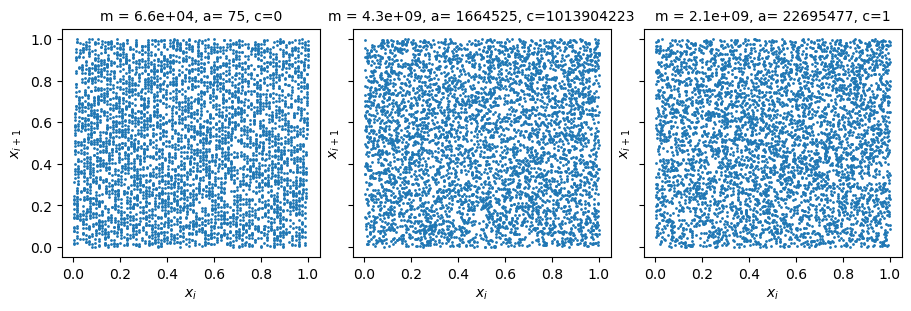

In [57]:
import matplotlib.pyplot as plt
import numpy as np

def PRNG(m,a,c,seed,n_iter=5000):
    j = 0
    nums = []
    while j < n_iter:
        seed = (a * seed + c)%m
        nums.append(seed/m)
        j += 1
    return nums


params = [{'m': 2**16+1, 'a':75, 'c':0}, {'m': 2**32, 'a':1664525, 'c':1013904223},{'m': 2**31, 'a':	22695477, 'c':1}]
fig,ax = plt.subplots(1,3,constrained_layout=True,sharex=True,sharey=True)
fig.set_size_inches(9,3)
for a,p in zip(ax,params):
    seed = 314
    nums = PRNG(**p,seed=seed)
    a.scatter(nums[:-1],nums[1:],s=1)
    a.set_title('m = {m:.1e}, a= {a}, c={c}'.format(**p),fontsize=10)
    a.set_xlabel(r'$x_{i}$')
    a.set_ylabel(r'$x_{i+1}$')


In python, `numpy.random` contains a number of pseudo-random sampling functions:

Some basic sampling:
`np.random.random()`: random float between 0 and 1  
`np.random.randrange(n)`: random int between 0 and n-1  
`np.random.randrange(m,n)`: random int between m and n-1

But we can also do other probability distributions ([full list](https://numpy.org/doc/stable/reference/random/generator.html#distributions))

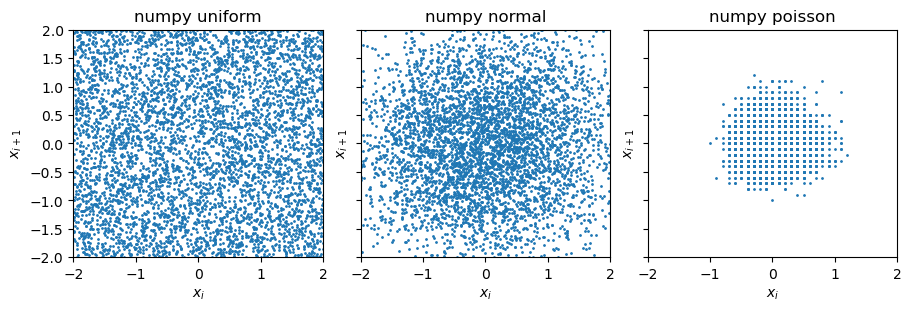

In [55]:
from numpy.random import default_rng
rng = default_rng()


fig,ax = plt.subplots(1,3,constrained_layout=True,sharex=True,sharey=True)
fig.set_size_inches(9,3)
nums = rng.uniform(-2,2,5000)
ax[0].scatter(nums[:-1],nums[1:],s=1)
ax[0].set_title('numpy uniform')
ax[0].set_xlabel(r'$x_{i}$')
ax[0].set_ylabel(r'$x_{i+1}$')

nums = rng.standard_normal(5000)
ax[1].scatter(nums[:-1],nums[1:],s=1)
ax[1].set_title('numpy normal')
ax[1].set_xlabel(r'$x_{i}$')
ax[1].set_ylabel(r'$x_{i+1}$')

nums = rng.poisson(10,5000)/10 - 1
ax[2].scatter(nums[:-1],nums[1:],s=1)
ax[2].set_title('numpy poisson')
ax[2].set_xlabel(r'$x_{i}$')
ax[2].set_ylabel(r'$x_{i+1}$')

for a in ax:
    a.set_xlim(-2,2)
    a.set_ylim(-2,2)


### Distribution Interlude
By default, the PRNG generates random numbers from a uniform distribution between 0 and 1. You can use other functions in `numpy` to change the range, but many primitive languages will only generate uniform distributions between 0 and 1, so it's good to practice identifying what is being sampled when these samples are modified.

Take `x = rng.random(N)` a list of $N$ random numbers between 0 and 1. Try to figure out how the resulting points should be distributed for each line of code.

1. `X = 0.5 * x`
2. `X = x - 0.5`
3. `theta = np.arccos(x), X = np.cos(theta), Y= np.sin(theta)`
4. ` theta = rng.random(len(x))*np.pi/2, X = np.sqrt(x) * np.cos(theta), Y = np.sqrt(x) * np.sin(theta)`
5. ` theta = rng.random(len(x))*np.pi/2, X = x * np.cos(theta), Y = x * np.sin(theta)`

```{embed} ex_11-2
```
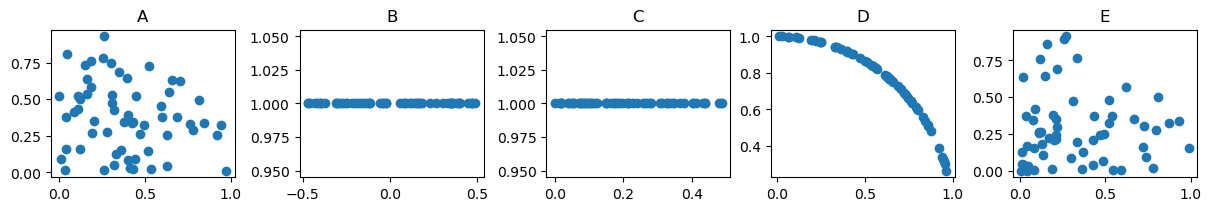

```{embed} sol_11-2
```

Text(0.5, 1.0, 'E')

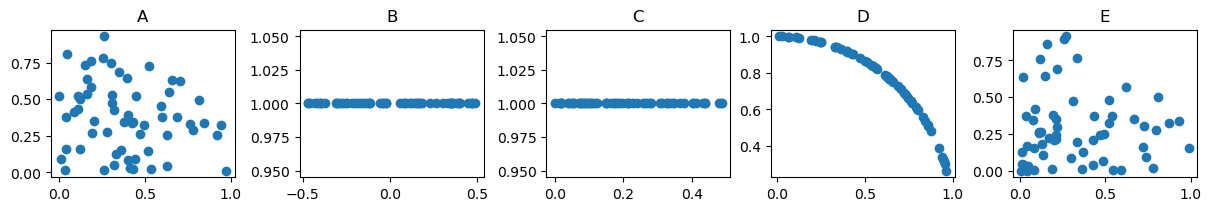

In [88]:
fig,ax = plt.subplots(1,5,constrained_layout=True)
fig.set_size_inches(12,2)

rng = default_rng()
X = 0.5 * rng.random(60)
ax[2].scatter(X, np.ones_like(X))
ax[2].set_title('C')
X = rng.random(60) - 0.5
ax[1].scatter(X, np.ones_like(X))
ax[1].set_title('B')
X = rng.random(60)
Y = np.sin(np.arccos(X))
ax[3].scatter(X, Y)
ax[3].set_title('D')
x = np.sqrt(rng.random(60))
theta = rng.random(60)*np.pi/2
X = x * np.cos(theta)
Y = x * np.sin(theta)
ax[0].scatter(X, Y)
ax[0].set_title('A')

x = rng.random(60)
theta = rng.random(60)*np.pi/2
X = x * np.cos(theta)
Y = x * np.sin(theta)
ax[4].scatter(X, Y)
ax[4].set_title('E')

## Ex: Monte Carlo Radioisotope Decay
Radioisotope decay is a random process wherein unstable (parent) nuclei decay by emission of a particle into a more stable (daughter) isotope. 

We describe this process with an expression for the evolution of the number of parent isotope $N$ over time $t$ given an initial number $N_0$ and a *half-life* $\tau$:

$$ N(t) = N_0 2^{-t/\tau}$$

For this statistical process, we can write the probability of a single parent atom decaying over some time $t$ in terms of the fraction that have decayed at that time $N(t)/N_0$:

$$ p(t) = 1 - N(t)/N_0 = 1 - 2^{-t/\tau}$$

❓

```{embed} ex_11-1
```

```{embed} sol_11-1
```


```{note} Decay algorithm
So if we want to think about this iteratively:

+ At each timestep, each remaining thallium atom can be represented by drawing a random number uniformly distributed between 0 and 1. 

+ For a uniform distribution between 0 and 1, the probability of pulling a random number **less than** some number $p$ is equal to $p$. 

+ Thus, we can determine how many thallium atoms decay that timestep by comparing their random draw to the probability $p(\Delta t)$. 
```

<h2><span class="fa fa-flash"></span> In-Class Coding Exercise </h2>

```{embed} icc_11-1
```

We can see that in this case, our model curve $N(t)$ describes the *average behavior* of a system that has inherent stochasticity. We can use it as ground truth *only* in so far as our code should reproduce similar behavior *on average*. 

Meaning, the deviation from $N(t)$ we are simulating here from timestep to timestep is not error but a realistic deviation due to the inherent randomness of the process that we can't capture analytically. 

In the previous example, we iterated recursively through time, drawing new probabilities based on a uniform distribution for each remaining atom. This method is straightforward enough.

## Ex: Radioactive decay II
What if we were interested in the probability of decay at some *specific* time between $t$ and $t+\Delta t$?

First, we need to know what the probability an atom survives to time $t$:

$$ p_s(t) = N(t)/N_0 = 2^{-t/\tau} $$

Then, we use the probability it decays between $t$ and $t + \delta t$ from before (which we will simply under the assumption that $\delta t \ll \tau$$)

$$ p_d(t+\delta t) = 1 - 2^{-\delta t/\tau} = 1 - \exp{(-\delta t \ln 2 /\tau)} = \frac{\ln 2}{\tau}dt$$

So the total probability that the atom decays at a specific time is given by:

$$P(t)dt = p_s(t) \cdot p_d(t+\delta t) = 2^{-t/\tau} \frac{\ln 2}{\tau} dt$$

We can additionally transform this into a more common exponential PDF:

$$P(t)dt = \exp{-(\ln 2 t/\tau)} \frac{\ln 2}{\tau} dt = \mu e^{\mu t} dt$$

where $\mu = \ln 2/\tau$. 

This gives us an alternative (and more efficient) method for computing radioactive decay than the previous example:

Instead of iterating through every time, we could **calculate directly** the time at which each atom decays by sampling the times from this (non-uniform!) probability distribution. 

Since this is a known form, `numpy.random` lets us directly sample from an [exponential distribution](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.exponential.html#numpy.random.Generator.exponential), so we could just directly draw from the sample there. 

But, then we'd miss out on a cool math trick to sample from arbitrary PDFs! (Also, if we didn't have a PDF in a convenient form that `numpy` knows about, we'd still need to sample from it)

```{note} Sampling from Non-Uniform distributions
Say you have a non-uniform PDF $p(x)$ of some random variable $x$ that you want to sample from.

You can write the variable $x$ as a function of some uniformly distributed variable $z$.

You can solve for the function $x(z)$ by solving:

$$ \int_{-\inf}^x(z) p(x') dx' = z $$


1. Draw the variable $z$ from a uniform distribution between 0 and 1.

2. Calculate $x(z)$ from your random samples $z$
```





<h2><span class="fa fa-flash"></span> In-Class Coding Exercise </h2>

```{embed} icc_11-2
```